Necessary Imports

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import classification_report, precision_recall_fscore_support
from sklearn.feature_selection import mutual_info_classif
from scipy.sparse import csr_matrix
from bs4 import BeautifulSoup
import re
import matplotlib.pyplot as plt

Implementing Logistic Regression with Stochastic Gradient Descent and Regularization

In [1]:
class LogisticRegressionSGD:
    def __init__(self, learning_rate=0.01, epochs=1000, regularization=0.1):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.regularization = regularization

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        self.weights = np.zeros(X.shape[1])
        self.bias = 0

        for epoch in range(self.epochs):
            for i in range(X.shape[0]):
                linear_model = np.dot(X[i], self.weights) + self.bias
                y_predicted = self.sigmoid(linear_model)

                # Gradient calculation
                dw = (y_predicted - y[i]) * X[i] + self.regularization * self.weights
                db = (y_predicted - y[i])

                # Weight update
                self.weights -= self.learning_rate * dw
                self.bias -= self.learning_rate * db

    def predict(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        y_predicted = self.sigmoid(linear_model)
        return [1 if i > 0.5 else 0 for i in y_predicted]


Loading the IMBD Dataset

In [4]:
file_path = '/Users/pckiousis/Downloads/IMDB Dataset.csv'
imdb_data = pd.read_csv(file_path)
imdb_data['sentiment'] = imdb_data['sentiment'].map({'positive': 1, 'negative': 0})


Text cleaning and getting a subset from our main dataset for faster processing

In [5]:
def clean_text(text):
    try:
        text = BeautifulSoup(text, "html.parser").get_text()
    except Exception:
        text = str(text)

    text = re.sub(r'[^a-zA-Z\s]', '', text).lower()
    return text

imdb_data['cleaned_review'] = imdb_data['review'].apply(clean_text)


subset_size = 5000
imdb_subset = imdb_data.sample(n=subset_size, random_state=42)


vectorizer_full = CountVectorizer(binary=True, stop_words='english')  # CountVectorizer for counting word existence in the subsets
X_full_counts = vectorizer_full.fit_transform(imdb_subset['cleaned_review'])
word_freq = np.asarray((X_full_counts > 0).sum(axis=0)).flatten()

/var/folders/tx/6xkjd5sj2939z8hlssc2tdhr0000gp/T/ipykernel_18056/3800838140.py:3: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  text = BeautifulSoup(text, "html.parser").get_text()


Removing n most frequent and k most rare words and selecting m words with highest Information Gain

In [16]:
n = 100
k = 100
valid_indices = np.argsort(word_freq)[k:len(word_freq) - n]
X_filtered_counts = X_full_counts[:, valid_indices]
filtered_vocab = np.array(vectorizer_full.get_feature_names_out())[valid_indices]
m = 1000
mutual_info = mutual_info_classif(X_filtered_counts, imdb_subset['sentiment'], discrete_features=True)
top_m_indices = np.argsort(mutual_info)[-m:]
X_final_counts = X_filtered_counts[:, top_m_indices]
final_vocab = filtered_vocab[top_m_indices]


Splitting data into train, development and test sets

In [12]:
X_train, X_temp, y_train, y_temp = train_test_split(X_final_counts, imdb_subset['sentiment'], test_size=0.4, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)
y_train = y_train.to_numpy()
y_temp = y_temp.to_numpy()
y_dev = y_dev.to_numpy()
y_test = y_test.to_numpy()


Training Logistic Regression Model focusing on the positive category

In [13]:
train_sizes = [100, 500, 1000,X_train.shape[0]]
precision_dev, recall_dev, f1_dev = [], [], []
precision_train, recall_train, f1_train = [], [], []

for size in train_sizes:
    X_train_subset = X_train[:size].toarray()
    y_train_subset = y_train[:size]

    lr_model = LogisticRegressionSGD(learning_rate=0.01, epochs=1000, regularization=0.1)
    lr_model.fit(X_train_subset, y_train_subset)

    # Evaluate on development data
    y_pred_dev = lr_model.predict(X_dev.toarray())
    precision, recall, f1, _ = precision_recall_fscore_support(y_dev, y_pred_dev, average=None, labels=[1])
    precision_dev.append(precision[0])
    recall_dev.append(recall[0])
    f1_dev.append(f1[0])

    # Evaluate on training subset
    y_pred_train = lr_model.predict(X_train_subset)
    precision, recall, f1, _ = precision_recall_fscore_support(y_train_subset, y_pred_train, average=None, labels=[1])
    precision_train.append(precision[0])
    recall_train.append(recall[0])
    f1_train.append(f1[0])


Plotting learning curves

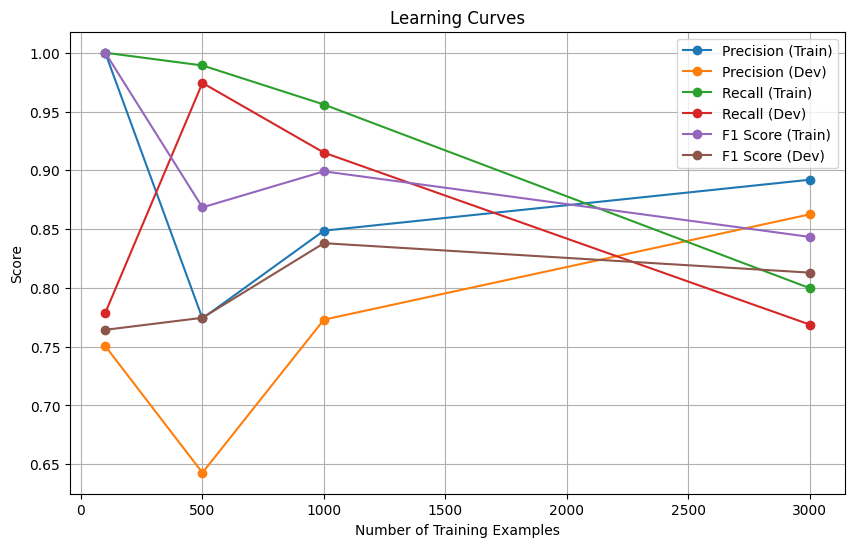

In [14]:
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, precision_train, label="Precision (Train)", marker='o')
plt.plot(train_sizes, precision_dev, label="Precision (Dev)", marker='o')
plt.plot(train_sizes, recall_train, label="Recall (Train)", marker='o')
plt.plot(train_sizes, recall_dev, label="Recall (Dev)", marker='o')
plt.plot(train_sizes, f1_train, label="F1 Score (Train)", marker='o')
plt.plot(train_sizes, f1_dev, label="F1 Score (Dev)", marker='o')
plt.title("Learning Curves")
plt.xlabel("Number of Training Examples")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

Evaluating results on the test data

In [15]:
lr_model_full = LogisticRegressionSGD(learning_rate=0.01, epochs=1000, regularization=0.1)
lr_model_full.fit(X_train.toarray(), y_train)

y_pred_test = lr_model_full.predict(X_test.toarray())
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred_test, average=None, labels=[0, 1])
micro_avg = precision_recall_fscore_support(y_test, y_pred_test, average='micro')
macro_avg = precision_recall_fscore_support(y_test, y_pred_test, average='macro')


print("\nTest Data Precision, Recall, F1 Scores:")
print(f"Class 0: Precision: {precision[0]:.2f}, Recall: {recall[0]:.2f}, F1: {f1[0]:.2f}")
print(f"Class 1: Precision: {precision[1]:.2f}, Recall: {recall[1]:.2f}, F1: {f1[1]:.2f}")
print(f"Micro Average: Precision: {micro_avg[0]:.2f}, Recall: {micro_avg[1]:.2f}, F1: {micro_avg[2]:.2f}")
print(f"Macro Average: Precision: {macro_avg[0]:.2f}, Recall: {macro_avg[1]:.2f}, F1: {macro_avg[2]:.2f}")



Test Data Precision, Recall, F1 Scores:
Class 0: Precision: 0.79, Recall: 0.89, F1: 0.84
Class 1: Precision: 0.87, Recall: 0.75, F1: 0.81
Micro Average: Precision: 0.82, Recall: 0.82, F1: 0.82
Macro Average: Precision: 0.83, Recall: 0.82, F1: 0.82
